# Questão 5 — Autoencoders: reconstrução, vetor latente e remoção de ruído

Este notebook resolve a **Q5a**, comparando representações latentes de 100, 50 e 30 dimensões, e a **Q5b**, treinando um novo autoencoder de denoising com vetor de 50 dimensões. O estudo usa Fashion-MNIST e documenta os dados, a arquitetura, as decisões metodológicas e a análise dos resultados.

O notebook contém gráficos e resultados da execução registrada. A reprodução em uma nova sessão requer a execução sequencial das células, pois os pesos treinados não são armazenados como objetos utilizáveis nas saídas das figuras.

| Parte | Entrada durante o treinamento | Resposta esperada | Comparação |
|---|---|---|---|
| Q5a | Imagem limpa | A própria imagem limpa | Vetores latentes 100, 50 e 30 |
| Q5b | Imagem com ruído | Imagem original limpa | Erro antes e depois do denoising |

Não utilizamos as classes das roupas para treinar um classificador. Os nomes de peças presentes no código são apenas uma referência descritiva.


## Conceitos e procedimentos de treinamento

Os modelos são descritos em termos das entradas, dos parâmetros aprendidos, da função de perda e do protocolo de avaliação. As definições a seguir estabelecem a terminologia utilizada na análise.


- **Exemplo ou observação:** uma entrada acompanhada da resposta conhecida. Um lote reúne vários exemplos para uma atualização dos pesos.
- **Atributo:** uma informação de entrada. O **alvo** é aquilo que queremos prever. Atributos não devem conter a própria resposta ou informações indisponíveis no momento de prever.
- **Neurônio e camada densa:** cada neurônio calcula uma combinação ponderada das entradas, soma um viés e aplica uma ativação. Em uma camada densa, cada neurônio recebe todas as saídas da camada anterior. Pesos e vieses são os parâmetros aprendidos.
- **Ativação:** introduz uma transformação não linear. ReLU calcula `max(0, x)`; Tanh é suave e varia de −1 a 1; Sigmoid varia de 0 a 1. Uma saída linear não impõe esses limites. A escolha depende da tarefa e deve ser avaliada no contexto do treinamento.
- **Função de perda:** transforma a diferença entre resposta e previsão em um número a minimizar. Uma métrica de avaliação pode coincidir com a perda, mas também pode medir outro aspecto do desempenho.
- **Gradiente e retropropagação:** o gradiente indica como a perda varia em relação a cada parâmetro. A retropropagação calcula esses gradientes ao percorrer as operações da rede em sentido inverso.
- **Adam:** otimizador que usa estimativas acumuladas dos gradientes e de seus quadrados para atualizar os parâmetros. A taxa de aprendizado controla a escala dos ajustes. Adam e retropropagação cumprem funções complementares.
- **Época:** uma passagem pelos exemplos de treino. **Batch size** é a quantidade de exemplos em cada lote. Mais épocas aumentam o trabalho de otimização, mas não garantem melhor desempenho em dados novos.
- **Early stopping:** monitora uma perda em dados separados, espera um número de épocas sem melhora e interrompe o treinamento. Quando solicitado, restaura os pesos da melhor época monitorada. A técnica limita o sobreajuste, mas não garante eliminá-lo.
- **Semente:** controla parte da aleatoriedade, como divisão e inicialização. Repetir sementes ajuda a observar a sensibilidade do resultado; não substitui testar em amostras independentes.
- **Generalização e sobreajuste:** generalizar é manter desempenho em dados não usados para ajustar os pesos. Quando o treino melhora e a avaliação separada estagna ou piora, há indício de que parte do aprendizado deixou de se transferir.

**Média e desvio-padrão.** A média resume as repetições, e o desvio descreve sua dispersão. É necessário verificar se as repetições mudam a inicialização ou também a divisão dos dados. Esse símbolo não representa variação por época nem um intervalo de confiança.


## 1. Formulação do autoencoder

Um **autoencoder** aprende a reconstruir seus dados de entrada. O **encoder** transforma uma imagem em uma representação; o **decoder** usa essa representação para gerar uma imagem reconstruída. Chamamos a representação intermediária de **vetor latente** ou **gargalo**.

Uma imagem 28×28 em tons de cinza tem 784 intensidades de pixels. Na Q5a, o gargalo tem 100, 50 ou 30 números. Essa restrição estimula a rede a preservar informações úteis à reconstrução. Cada componente latente é aprendido; não há garantia de que corresponda diretamente a uma ideia interpretável como “manga”, “salto” ou “cor”.

**Compressão da representação** não equivale a uma comparação de tamanho de arquivos: números latentes são floats, pixels têm outra codificação e o decoder também precisa ser armazenado. O experimento mede reconstrução sob diferentes dimensões do gargalo, sem avaliar um codec de compressão completo.

A arquitetura segue a organização encoder–gargalo–decoder discutida no projeto e compatível com os princípios de autoencoders do material de aula. A implementação convolucional aproveita a vizinhança espacial dos pixels. Os números de filtros 32 e 64 são escolhas de configuração, não valores demonstrados como ótimos por uma busca.

### Perda e avaliação

O MSE compara cada pixel real $x_{i,p}$ com sua reconstrução $\hat x_{i,p}$:

$$\mathrm{MSE}=\frac{1}{N\cdot784}\sum_{i=1}^{N}\sum_{p=1}^{784}(x_{i,p}-\hat x_{i,p})^2.$$

Menor MSE indica maior proximidade segundo essa medida. Com pixels em [0,1], os erros também ficam em uma escala controlada. MSE **não é percentual de erro**, não é accuracy e não mede sozinho a qualidade perceptual: uma saída suavizada pode reduzir o erro médio e apagar detalhes.

Na Q5a, a métrica global usa **10.000 imagens de teste**. Na Q5b, a métrica mostrada usa **as mesmas dez imagens selecionadas para a figura**. Essa diferença de amostra limita a comparação entre os resultados; comparar os números entre as partes como se fossem o mesmo protocolo seria inadequado.


## 2. Ambiente e reprodutibilidade 

Importamos bibliotecas para matrizes, figuras e modelos Keras. Algumas importações vieram do ambiente geral do projeto e não são necessárias à Q5 isolada. As sementes de Python, NumPy e TensorFlow são fixadas em 42; isso ajuda a rastrear a execução, mas bibliotecas, dispositivos e sequência de operações aleatórias podem mudar resultados.

O modo **completo** carrega todos os dados e permite 15 épocas. O modo rascunho reduz dados e treinamento e corresponde a outro experimento. A saída salva registra TensorFlow 2.21.0 e ausência de GPU. GPU pode reduzir o tempo; não é requisito conceitual para o método.

Separar a Q5 do notebook original altera a sequência de operações anterior à inicialização das redes. Uma nova execução independente pode produzir métricas diferentes das preservadas, mesmo com semente 42.


In [1]:
import os, random, zipfile, urllib.request, io
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_absolute_error, mean_squared_error, accuracy_score,
    precision_recall_fscore_support, classification_report, confusion_matrix)
from sklearn.utils.class_weight import compute_class_weight

SEMENTE=42
os.environ["PYTHONHASHSEED"]=str(SEMENTE)
random.seed(SEMENTE); np.random.seed(SEMENTE); tf.random.set_seed(SEMENTE)
MODO_EXECUCAO="completo"  # use "rascunho" durante desenvolvimento
sns.set_theme(style="whitegrid",context="notebook")
print("TensorFlow:",tf.__version__)
print("GPU(s):",tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU(s): []


## 3. Q5a — dados, arquitetura e treinamento

### Procedimento de preparação e treinamento

1. Carrega Fashion-MNIST com **60.000 imagens de treinamento e 10.000 de teste**. Os rótulos são descartados com `_` porque a tarefa é reconstrução.
2. Converte para `float32`, divide por 255 e acrescenta o eixo do canal: `(N,28,28,1)`. Dividir por uma constante conhecida não estima estatísticas do teste.
3. Define uma função que constrói um autoencoder a partir do tamanho do vetor latente.
4. Cria três redes novas, de dimensões 100, 50 e 30, e treina cada uma com imagem limpa como entrada e alvo.

### Fluxo pela arquitetura

| Etapa | Operação | Formato por imagem | Papel |
|---|---|---|---|
| Entrada | Pixels em [0,1] | 28×28×1 | Imagem limpa |
| Encoder 1 | Conv 3×3, 32 filtros, ReLU | 28×28×32 | Aprender padrões locais |
| Redução 1 | MaxPooling 2×2 | 14×14×32 | Reduzir resolução |
| Encoder 2 | Conv 3×3, 64 filtros, ReLU | 14×14×64 | Combinar padrões |
| Redução 2 | MaxPooling 2×2 | 7×7×64 | Reduzir resolução novamente |
| Vetorização | Flatten | 3.136 | Reorganizar mapas em vetor |
| Gargalo | Densa linear | 100, 50 ou 30 | Representação compacta |
| Expansão | Densa ReLU | 3.136 | Gerar representação para o decoder |
| Reorganização | Reshape | 7×7×64 | Retomar formato espacial |
| Decoder 1 | ConvTranspose 3×3, 64, passo 2, ReLU | 14×14×64 | Aumentar resolução |
| Decoder 2 | ConvTranspose 3×3, 32, passo 2, ReLU | 28×28×32 | Recuperar resolução de entrada |
| Saída | Conv 3×3, 1 filtro, Sigmoid | 28×28×1 | Reconstruir intensidades |

**Convolução** aplica filtros locais com pesos compartilhados. `padding="same"` mantém a resolução quando o passo é 1. **MaxPooling** seleciona a maior ativação em regiões 2×2, reduzindo a resolução. Flatten e reshape reorganizam números, sem aprender pesos. **Convolução transposta** aprende uma transformação que aumenta a resolução com passo 2; não é uma inversão matemática exata das convoluções do encoder. A camada final é uma convolução comum, não transposta.

ReLU introduz não linearidade nas representações. A densa do gargalo é linear, pois não declara ativação. Sigmoid limita cada pixel reconstruído a [0,1], coerente com a preparação. Ela não representa probabilidade de uma classe de roupa.

### Por que comparar 100, 50 e 30

Os três valores investigam um compromisso: uma representação menor pode perder detalhes, enquanto uma maior preserva mais informação. Mantemos os tipos e a ordem das camadas, mas **o número de parâmetros também muda**, pois as camadas conectadas ao gargalo dependem de sua dimensão. Portanto, o efeito observado não é uma mudança de representação com quantidade de parâmetros fixa.

Os tamanhos são alternativas experimentais, sem afirmar que incluem o melhor valor possível. Cada rede é inicializada e treinada separadamente. Não há repetição com várias sementes por dimensão nem demonstração de significância estatística.

### Receita de treinamento

Usamos Adam com taxa 0,001, perda MSE, lote 128 e até 15 épocas. `validation_split=0.10` separa as últimas 6.000 imagens da parte fornecida ao `fit`, antes do embaralhamento de treino: ficam **54.000 para ajustar pesos e 6.000 para monitorar**. A divisão não é estratificada; rótulos não são usados.

Early stopping acompanha `val_loss`, espera três épocas sem melhoria e restaura os melhores pesos. Os registros mostram as 15 épocas nas três redes: atingir o teto não demonstra convergência, e as perdas ainda apresentam pequenas melhorias. Os dicionários `aes` e `h_ae` guardam redes e históricos na sessão, mas não exportam pesos para arquivos nesta célula.


In [20]:
(xf_train,_),(xf_test,_)=keras.datasets.fashion_mnist.load_data()
xf_train=xf_train.astype("float32")[...,None]/255.; xf_test=xf_test.astype("float32")[...,None]/255.
if MODO_EXECUCAO=="rascunho": xf_train=xf_train[:12000]; xf_test=xf_test[:2000]
print("Fashion-MNIST:",xf_train.shape,xf_test.shape)
nomes_fashion=["camiseta","calça","pulôver","vestido","casaco","sandália","camisa","tênis","bolsa","bota"]
def criar_autoencoder(latente=50,nome="autoencoder"):
    entrada=keras.Input((28,28,1),name="imagem")
    x=layers.Conv2D(32,3,activation="relu",padding="same")(entrada); x=layers.MaxPooling2D(2,padding="same")(x)
    x=layers.Conv2D(64,3,activation="relu",padding="same")(x); x=layers.MaxPooling2D(2,padding="same")(x)
    x=layers.Flatten()(x); z=layers.Dense(latente,name="vetor_latente")(x)
    x=layers.Dense(7*7*64,activation="relu")(z); x=layers.Reshape((7,7,64))(x)
    x=layers.Conv2DTranspose(64,3,strides=2,activation="relu",padding="same")(x)
    x=layers.Conv2DTranspose(32,3,strides=2,activation="relu",padding="same")(x)
    saida=layers.Conv2D(1,3,activation="sigmoid",padding="same",name="reconstrucao")(x)
    m=keras.Model(entrada,saida,name=nome); m.compile(optimizer=keras.optimizers.Adam(1e-3),loss="mse"); return m
DIMENSOES_LATENTES=[100,50,30]; aes={}; h_ae={}; EPOCAS_AE=15 if MODO_EXECUCAO=="completo" else 3
for dim in DIMENSOES_LATENTES:
    print("Treinando z=",dim); ae=criar_autoencoder(dim,nome=f"ae_latente_{dim}"); aes[dim]=ae
    h_ae[dim]=ae.fit(xf_train,xf_train,validation_split=.10,epochs=EPOCAS_AE,batch_size=128,
        callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss",patience=3,restore_best_weights=True)],verbose=1)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Fashion-MNIST: (60000, 28, 28, 1) (10000, 28, 28, 1)
Treinando z= 100
Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 204s 476ms/step - loss: 0.0293 - val_loss: 0.0137
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 175s 414ms/step - loss: 0.0115 - val_loss: 0.0100
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 209s 431ms/step - loss: 0.0091 - val_loss: 0.0085
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 170s 404ms/step - loss: 0.0079 - val_loss: 0.0076
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 197s 392ms/step - loss: 0.0072 - val_loss: 0.0070
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 167s 396ms/step - loss: 0.0067 - val_loss: 0.0065
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 169s 402ms/step - loss: 0.0063 - val_loss: 0.0062
Epoch 8/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 175s 414ms/step - loss: 0.0060 - val_loss: 0.0060
Epoch 9/15
422/422 ━━━

## 4. Q5a — comparar as mesmas imagens e medir erro

### Procedimento de avaliação

Selecionamos dez índices igualmente espaçados no teste usando `linspace`. Essa escolha é determinística e não depende do erro; não garante uma imagem de cada classe nem uma amostra representativa. Cada coluna da figura corresponde à **mesma imagem nas quatro linhas**:

| Linha | Conteúdo |
|---|---|
| 1 | Original limpa |
| 2 | Reconstrução com z=100 |
| 3 | Reconstrução com z=50 |
| 4 | Reconstrução com z=30 |

`squeeze` remove o eixo de canal de tamanho 1 para desenhar em tons de cinza. As reconstruções usam limites de exibição [0,1]. A tabela por imagem calcula erro médio sobre altura, largura e canal, deixando um valor por exemplo. Isso permite observar que uma dimensão menor pode superar outra em um exemplo particular, mesmo tendo erro global pior.

Depois das figuras, a célula calcula previsões para **todo o teste** em lotes de 256 e faz a média dos erros quadráticos em todas as imagens e pixels. Lote de predição organiza o processamento; não altera a definição da métrica. As dez imagens ilustradas não são a única fonte do MSE global.


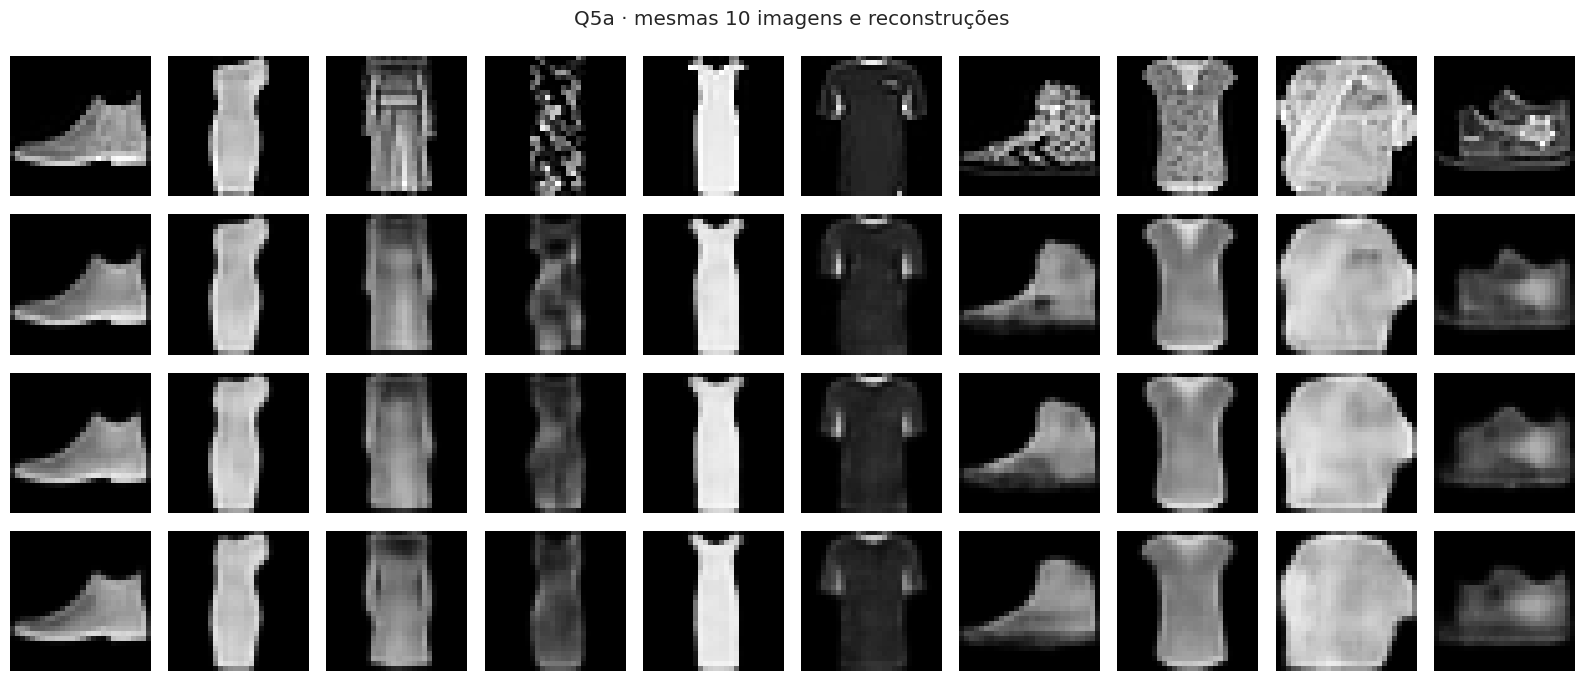

MSE médio no conjunto de teste:


z=100: 0.005024
z= 50: 0.006197
z= 30: 0.007267


,latente_100,latente_50,latente_30
0,0.000985,0.001554,0.001795
1,0.001324,0.001944,0.002721
2,0.006264,0.007218,0.006970
3,0.013862,0.016926,0.018438
4,0.003310,0.004253,0.003877
5,0.002333,0.002836,0.003248
6,0.010952,0.012141,0.013944
7,0.003305,0.003889,0.004946
8,0.009747,0.013306,0.017766
9,0.006659,0.006937,0.008100


In [21]:
idx_f=np.linspace(0,len(xf_test)-1,10,dtype=int); orig=xf_test[idx_f]
preds={d:aes[d].predict(orig,verbose=0) for d in DIMENSOES_LATENTES}
erros_ae={d:np.mean((orig-preds[d])**2,axis=(1,2,3)) for d in DIMENSOES_LATENTES}
fig,axs=plt.subplots(4,10,figsize=(16,7))
for j in range(10):
    axs[0,j].imshow(orig[j].squeeze(),cmap="gray"); axs[0,j].axis("off")
    for i,d in enumerate(DIMENSOES_LATENTES,1):
        axs[i,j].imshow(preds[d][j].squeeze(),cmap="gray",vmin=0,vmax=1); axs[i,j].axis("off")
        if j==0: axs[i,j].set_ylabel(f"z={d}",rotation=0,labelpad=25)
axs[0,0].set_ylabel("original",rotation=0,labelpad=30); plt.suptitle("Q5a · mesmas 10 imagens e reconstruções")
plt.tight_layout(); plt.show()
print("MSE médio no conjunto de teste:")
for d in DIMENSOES_LATENTES:
    pred_full=aes[d].predict(xf_test,batch_size=256,verbose=0); print(f"z={d:3d}: {np.mean((xf_test-pred_full)**2):.6f}")
display(pd.DataFrame({f"latente_{d}":erros_ae[d] for d in DIMENSOES_LATENTES}))

### Resultados observados da Q5a

| Dimensão latente | MSE nas 10.000 imagens de teste | Aumento relativo a z=100 |
|---|---:|---:|
| 100 | **0,005024** | Referência |
| 50 | 0,006197 | Aproximadamente 23,3% |
| 30 | 0,007267 | Aproximadamente 44,6% |

A redução do gargalo aumentou o erro global nesta execução. O vetor de 100 dimensões foi o melhor segundo MSE, enquanto o de 30 é o mais compacto entre os testados. A comparação evidencia uma troca, não torna a dimensão menor inadequada para qualquer aplicação. O aumento percentual é calculado sobre o MSE de referência, não sobre uma taxa de acertos.

Os logs finais de validação ficaram aproximadamente em 0,0050, 0,0062 e 0,0073 para z=100, 50 e 30. Eles são perdas de monitoramento, distintas do MSE de teste da tabela. A proximidade das perdas de treino e validação não prova ausência completa de sobreajuste; não há aqui uma avaliação repetida para estimar variância.

A comparação visual permite examinar a preservação da silhueta e a perda de detalhes finos. Uma reconstrução visualmente mais suave pode ter erro médio baixo. A conclusão quantitativa sustentada é a ordenação do MSE global, e não que todas as imagens tenham a mesma ordenação individual.


## 5. Q5b — um novo autoencoder para remover ruído

**Denoising** significa reconstruir uma versão limpa a partir de uma entrada degradada. Criamos um modelo novo com **50 dimensões latentes**. A rede anterior de z=50 não é reutilizada com os pesos já aprendidos; a função constrói outra instância e a treina com pares entrada ruidosa → alvo limpo.

O valor 50 é uma escolha intermediária entre os tamanhos anteriores, não o resultado de uma comparação de tamanhos para denoising. Não afirmamos que seja o melhor para essa tarefa. A estrutura de encoder/decoder, Adam, MSE, lote e teto de épocas são os mesmos da Q5a.

### Distribuição do ruído e procedimento experimental

Adicionamos ruído gaussiano independente, com média zero e desvio-padrão **0,25 na escala [0,1]**. Um desvio de 0,25 não significa “25% dos pixels corrompidos”. Somamos perturbações e aplicamos `clip` para manter os valores em [0,1]. Após esse recorte, a distribuição efetiva deixa de ser exatamente gaussiana, especialmente perto de preto e branco.

As sementes 43 e 44 produzem ruídos de treino e de avaliação separados. A função gera o conjunto ruidoso uma vez: não cria novo ruído a cada época. Assim, o modelo vê as mesmas realizações para cada imagem ao repetir épocas. O embaralhamento muda a ordem dos exemplos, não o ruído associado.

Para validar, `validation_split=0.10` separa pares correspondentes nas últimas 6.000 imagens, mantendo alvos limpos e entradas ruidosas alinhados. Para avaliar visualmente, reutilizamos as mesmas dez imagens da Q5a. No grid de três linhas, a ordem é **limpa → ruidosa → reconstruída**.

Comparamos dois MSE contra o mesmo alvo: entrada ruidosa versus limpa e reconstrução versus limpa. Isso mede se a transformação aproxima a entrada da referência. Avaliar apenas reconstrução versus entrada ruidosa incentivaria preservar o ruído e não mediria o objetivo desejado.


Model: "ae_denoising_latente_50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagem (InputLayer)             │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vetor_latente (Dense)           │ (None, 50)             │       156,850 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 3136)           │       159,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_3 (Reshape)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_6              │ (None, 14, 14, 64)     │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_7              │ (None, 28, 28, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstrucao (Conv2D)           │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 391,283 (1.49 MB)

 Trainable params: 391,283 (1.49 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 177s 415ms/step - loss: 0.0385 - val_loss: 0.0176
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 195s 399ms/step - loss: 0.0156 - val_loss: 0.0139
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 168s 397ms/step - loss: 0.0129 - val_loss: 0.0122
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 167s 395ms/step - loss: 0.0116 - val_loss: 0.0114
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 166s 395ms/step - loss: 0.0107 - val_loss: 0.0109
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 170s 403ms/step - loss: 0.0101 - val_loss: 0.0102
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 168s 398ms/step - loss: 0.0097 - val_loss: 0.0099
Epoch 8/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 206s 409ms/step - loss: 0.0094 - val_loss: 0.0096
Epoch 9/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 173s 409ms/step - loss: 0.0092 - val_loss: 0.0094
Epoch 10/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 171s 406ms/step - loss: 0.0089 - val_loss: 0.0093
Epoch 11/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 208s 420ms/step - loss: 0.0088 - val_loss: 0.0092
Epoch 12

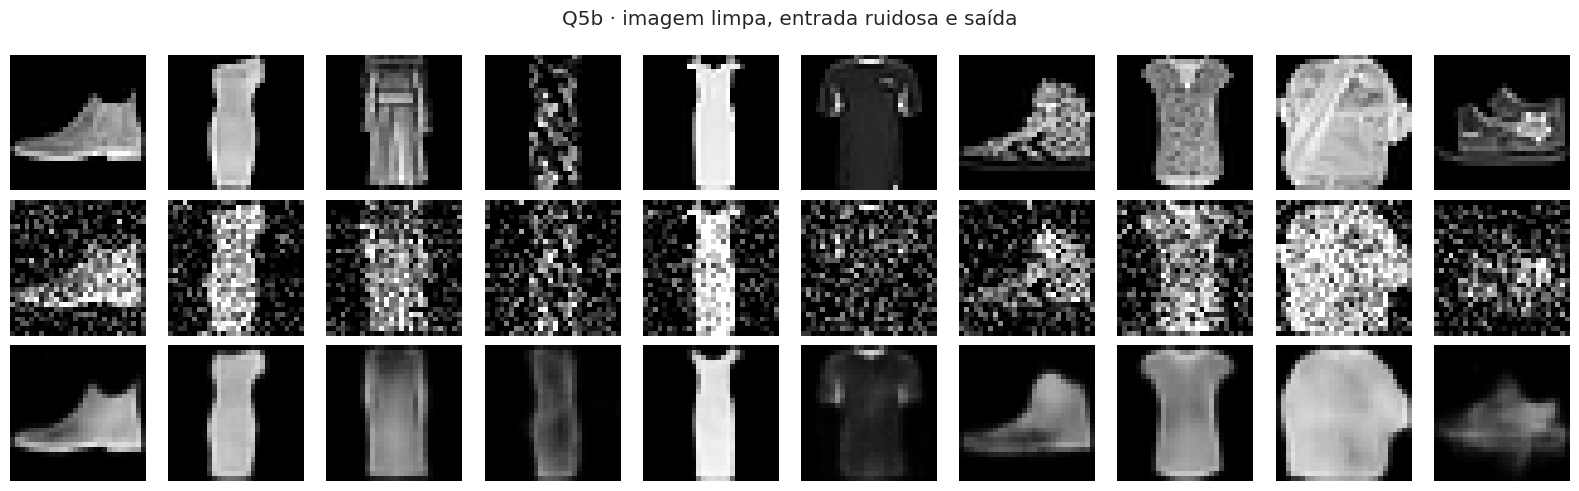

MSE ruidosa→limpa: 0.03889 | reconstruída→limpa: 0.00915


In [22]:
def adicionar_ruido(imagens,sigma=.25,seed=SEMENTE):
    gerador=np.random.default_rng(seed); return np.clip(imagens+gerador.normal(0,sigma,size=imagens.shape),0,1).astype("float32")
ruido_tr=adicionar_ruido(xf_train,seed=SEMENTE+1); ruido_teste=adicionar_ruido(orig,seed=SEMENTE+2)
ae_ruido=criar_autoencoder(50,nome="ae_denoising_latente_50"); ae_ruido.summary()
h_ruido=ae_ruido.fit(ruido_tr,xf_train,validation_split=.10,epochs=EPOCAS_AE,batch_size=128,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss",patience=3,restore_best_weights=True)],verbose=1)
rec_ruido=ae_ruido.predict(ruido_teste,verbose=0); fig,axs=plt.subplots(3,10,figsize=(16,5))
for j in range(10):
    for r,img in enumerate([orig[j],ruido_teste[j],rec_ruido[j]]):
        axs[r,j].imshow(img.squeeze(),cmap="gray",vmin=0,vmax=1); axs[r,j].axis("off")
        if j==0: axs[r,j].set_ylabel(["limpa","ruidosa","reconstruída"][r],rotation=0,labelpad=38)
plt.suptitle("Q5b · imagem limpa, entrada ruidosa e saída"); plt.tight_layout(); plt.show()
print("MSE ruidosa→limpa: {:.5f} | reconstruída→limpa: {:.5f}".format(np.mean((ruido_teste-orig)**2),np.mean((rec_ruido-orig)**2)))

## 6. Resultado da Q5b e limites da conclusão

| Comparação nas mesmas dez imagens | MSE |
|---|---:|
| Entrada ruidosa versus imagem limpa | 0,03889 |
| Reconstrução versus imagem limpa | **0,00915** |

A redução relativa é aproximadamente **76,5%**, calculada por `(0,03889 − 0,00915) / 0,03889`. A saída ficou mais próxima das imagens limpas segundo o MSE nesses dez exemplos. Isso não corresponde a 76,5% de accuracy, nem a uma garantia de remover qualquer tipo de ruído.

Nos logs, a perda de treino ao final ficou aproximadamente em 0,0083 e a de validação em 0,0088. O MSE 0,00915 é de outra amostra: os dez exemplos ilustrados. O modelo completou 15 épocas; o monitoramento ainda melhorava e não permite afirmar convergência completa.

Este experimento usa ruído sintético com intensidade fixa. Não testamos ruído de câmera, borramento, compressão JPEG ou outras intensidades. A suavização pode eliminar textura útil junto com o ruído. Não foram calculadas métricas perceptuais nem MSE de denoising nas 10.000 imagens; a evidência quantitativa reportada tem amostra pequena e deve ser apresentada assim.

### Decisões e justificativas, sem extrapolar os testes

| Decisão | Justificativa e limite |
|---|---|
| Autoencoder convolucional | Explorar padrões locais e reconstruir estrutura espacial; sem comparação com autoencoder denso |
| Dois estágios de redução | Reduzir 28→14→7 e permitir recuperação progressiva; não prova número ideal de camadas |
| Filtros 32 e 64 | Configuração adotada para aumentar canais ao reduzir resolução; sem busca desses valores |
| Gargalos 100, 50 e 30 | Comparação explícita de compactação e erro na Q5a |
| Sigmoid na saída | Compatibilidade com intensidades em [0,1] |
| MSE | Medida por pixel simples e coerente com o alvo de reconstrução; percepção exige leitura visual adicional |
| Novo modelo de z=50 na Q5b | Configuração intermediária; treinamento específico para entrada ruidosa |
| Mesmas dez imagens | Comparabilidade visual entre partes; amostra insuficiente para conclusão global de denoising |
| Sem classes no treinamento | O alvo é a imagem limpa, não a categoria de roupa |

## 7. Referências de apoio

- Fashion-MNIST, origem: https://github.com/zalandoresearch/fashion-mnist
- Keras, conjunto Fashion-MNIST: https://keras.io/api/datasets/fashion_mnist/
- Keras, convolução transposta: https://keras.io/api/layers/convolution_layers/convolution2d_transpose/
- Keras, parada antecipada: https://keras.io/api/callbacks/early_stopping/

As fontes são indicadas para consulta conceitual. Os números da análise vêm das saídas preservadas da execução corrigida.
